### **0. Environment Setup**

In [1]:
#Import Libs
import sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

In [2]:
#Define Colors Palette and Standards for Illustrations
RED, DARK, GRAY, LIGHT, SOFT = "#CD2027", "#404040", "#7F7F7F", "#D9D9D9", "#E9A0A3"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.prop_cycle": cycler(color=[RED, DARK, SOFT, GRAY]),
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

In [3]:
#Helper Functions: Evaluation Reports ( Confusion Matrix, Metrics, ROC and Precision-Recall )
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, log_loss, matthews_corrcoef,
                             confusion_matrix, roc_curve, precision_recall_curve)

def plot_confusion(cm, labels, ax, title="Confusion matrix"):
    ax.imshow(cm, cmap="Reds"); ax.grid(False)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45 if len(labels) > 4 else 0, ha="right" if len(labels) > 4 else "center")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10 if len(labels) > 4 else 13,
                    color="white" if cm[i, j] > cm.max() / 2 else DARK)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)

def report_binary(y_true, y_pred, y_score, name="model", labels=("negative", "positive"), plot=True):
    """Confusion matrix, ROC and Precision-Recall curves + a Series with the main metrics (positive class = 1)."""
    y_true, y_pred, y_score = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_score)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "precision": precision_score(y_true, y_pred, zero_division=0), "recall": recall_score(y_true, y_pred),
               "F1": f1_score(y_true, y_pred), "MCC": matthews_corrcoef(y_true, y_pred),
               "ROC AUC": roc_auc_score(y_true, y_score), "PR AUC": average_precision_score(y_true, y_score)}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
        plot_confusion(confusion_matrix(y_true, y_pred), list(labels), axes[0], f"Confusion matrix – {name}")
        fpr, tpr, _ = roc_curve(y_true, y_score)
        axes[1].plot(fpr, tpr, color=RED, lw=2.4, label=f"AUC = {metrics['ROC AUC']:.3f}"); axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--")
        axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")
        p, r, _ = precision_recall_curve(y_true, y_score)
        axes[2].plot(r, p, color=DARK, lw=2.4, label=f"AP = {metrics['PR AUC']:.3f}"); axes[2].axhline(y_true.mean(), color=GRAY, ls="--")
        axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision"); axes[2].set_title("Precision–Recall curve"); axes[2].legend(loc="lower left")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)

def report_multiclass(y_true, y_pred, y_proba, labels, name="model", plot=True):
    """Confusion matrix, one-vs-rest ROC curves and per-class F1 + a Series with the main metrics."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    k = len(labels)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "macro precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
               "macro recall": recall_score(y_true, y_pred, average="macro"), "macro F1": f1_score(y_true, y_pred, average="macro"),
               "MCC": matthews_corrcoef(y_true, y_pred), "ROC AUC (ovr)": roc_auc_score(y_true, y_proba, multi_class="ovr"),
               "log loss": log_loss(y_true, y_proba, labels=list(range(k)))}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.1, 1, 1]})
        plot_confusion(confusion_matrix(y_true, y_pred, labels=list(range(k))), list(labels), axes[0], f"Confusion matrix – {name}")
        cmap = plt.get_cmap("tab10")
        for c in range(k):
            fpr, tpr, _ = roc_curve((y_true == c).astype(int), y_proba[:, c])
            axes[1].plot(fpr, tpr, color=cmap(c), lw=1.6, label=f"{labels[c]}")
        axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
        axes[1].set_title(f"ROC one-vs-rest (macro AUC = {metrics['ROC AUC (ovr)']:.3f})"); axes[1].legend(fontsize=7, ncol=2 if k > 5 else 1, loc="lower right")
        f1s = f1_score(y_true, y_pred, average=None)
        axes[2].bar(range(k), f1s, color=RED, width=0.65); axes[2].set_xticks(range(k)); axes[2].set_xticklabels(labels, rotation=45 if k > 4 else 0, ha="right" if k > 4 else "center")
        axes[2].set_ylim(0, 1.05); axes[2].set_ylabel("F1"); axes[2].set_title("F1 per class")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)
def annotate_heatmap(ax, mat, fmt="{:.2f}"):
    """Write the values on an imshow heat map with a readable text color."""
    mat = np.asarray(mat, dtype=float)
    lo, hi = np.nanmin(mat), np.nanmax(mat)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat[i, j]
            ax.text(j, i, "–" if np.isnan(v) else fmt.format(v), ha="center", va="center", color="white" if (not np.isnan(v) and v > (lo + hi) / 2) else DARK)

### **1. Other Specific Algorithms**

| Algorithm | Family | Idea | Used for |
|---|---|---|---|
| **SVM** | margin / kernel methods | maximum-margin hyperplane, **kernel trick** | classification |
| **Genetic Algorithm (GA)** | evolutionary computation | selection · crossover · mutation of a **population** | search / feature selection |
| **Particle Swarm (PSO)** | swarm intelligence | particles follow their own and the swarm's best position | continuous optimisation, tuning |
| **Simulated Annealing (SA)** | trajectory metaheuristic | accept **worse** moves with probability $e^{-\Delta/T}$ while the **temperature** falls | combinatorial optimisation |
| **Fuzzy inference** | approximate reasoning | linguistic rules over **membership functions** | control, decision support |
| **Isolation Forest** | anomaly detection | anomalies are **isolated** with few random splits | outlier / novelty detection |

For the algorithms that **produce a model** (SVM, GA, PSO, fuzzy, Isolation Forest) we use the generic metrics (confusion matrix, ROC…). For the **optimisers** we add their own: **convergence, diversity, acceptance rate, stability across runs**.

In [4]:
#Load the Breast Cancer Dataset ( Positive Class = Malignant ), Split 70/30 and Standardise ( Fitted on the Training Set )
import time
from sklearn.pipeline import make_pipeline
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

bc = load_breast_cancer(as_frame=True)
X, y = bc.data, (bc.target == 0).astype(int)
names = list(X.columns)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
scaler = StandardScaler().fit(X_train)
Xs_tr, Xs_te = scaler.transform(X_train), scaler.transform(X_test)
ytr, yte = y_train.to_numpy(), y_test.to_numpy()
CLASSES = ["benign", "malignant"]
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = {}
print("train:", Xs_tr.shape, "| test:", Xs_te.shape, "| malignant in train:", f"{ytr.mean():.1%}")

train: (398, 30) | test: (171, 30) | malignant in train: 37.2%


### **2. Support Vector Machine (SVM)**

Finds the hyperplane with the **largest margin** between the classes. For a linear SVM the margin width is $2 / \lVert w \rVert$.

$$\min_{w,b,\xi}\ \frac{1}{2}\lVert w \rVert^2 + C \sum_i \xi_i \quad \text{s.t.}\ y_i (w^T x_i + b) \ge 1 - \xi_i$$

* **Support vectors:** the points on or inside the margin – the only ones that define the boundary
* **C:** large = narrow margin, few errors (risk of overfitting) · small = wide margin, more errors
* **Kernel trick:** the RBF kernel $K(x, x') = e^{-\gamma \lVert x - x' \rVert^2}$ gives **non-linear** boundaries; $\gamma$ controls how local they are

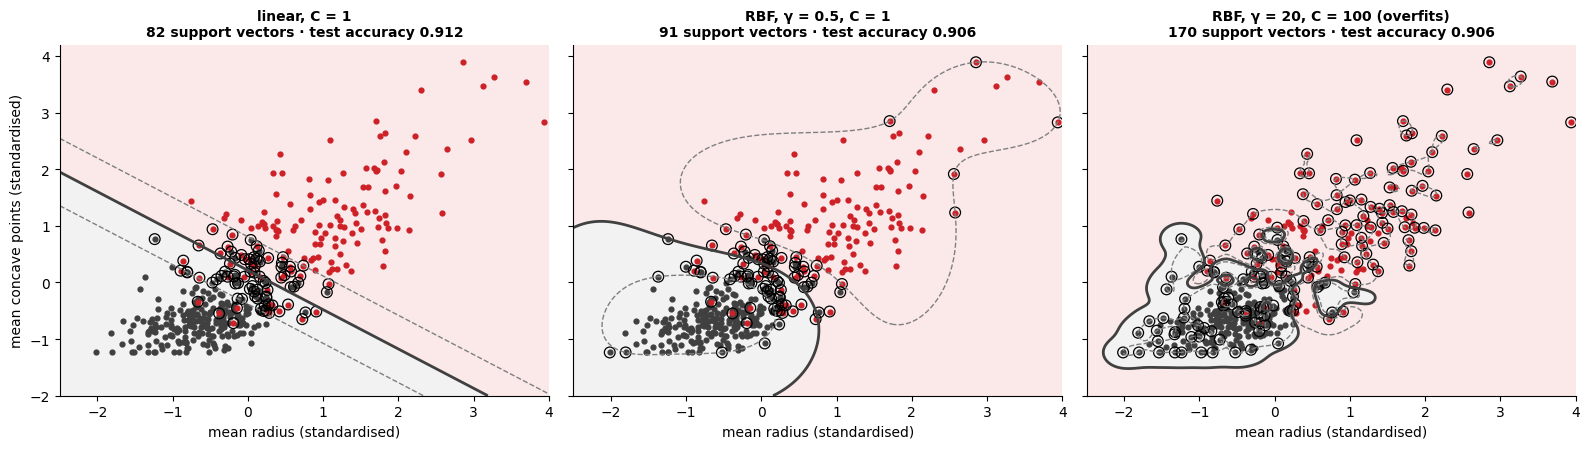

In [5]:
#Margin, Support Vectors and Kernels on Two Attributes ( Linear, RBF and a Too-Flexible RBF )
from sklearn.svm import SVC

two = ["mean radius", "mean concave points"]
sc2 = StandardScaler().fit(X_train[two])
X2_tr, X2_te = sc2.transform(X_train[two]), sc2.transform(X_test[two])
gx, gy = np.meshgrid(np.linspace(-2.5, 4, 250), np.linspace(-2, 4.2, 250))
grid = np.c_[gx.ravel(), gy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharex=True, sharey=True)
for ax, (title, model) in zip(axes, [("linear, C = 1", SVC(kernel="linear", C=1.0)), ("RBF, γ = 0.5, C = 1", SVC(kernel="rbf", gamma=0.5, C=1.0)), ("RBF, γ = 20, C = 100 (overfits)", SVC(kernel="rbf", gamma=20, C=100))]):
    model.fit(X2_tr, ytr)
    z = model.decision_function(grid).reshape(gx.shape)
    ax.contourf(gx, gy, z, levels=[z.min(), 0, z.max()], colors=["#F2F2F2", "#FBE9EA"])
    ax.contour(gx, gy, z, levels=[-1, 0, 1], colors=[GRAY, DARK, GRAY], linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
    ax.scatter(*X2_tr[ytr == 0].T, s=12, color=DARK); ax.scatter(*X2_tr[ytr == 1].T, s=12, color=RED)
    ax.scatter(*X2_tr[model.support_].T, s=60, facecolors="none", edgecolors="black", lw=0.9)
    ax.set_title(f"{title}\n{len(model.support_)} support vectors · test accuracy {model.score(X2_te, yte):.3f}", fontsize=10); ax.grid(False); ax.set_xlabel(two[0] + " (standardised)")
axes[0].set_ylabel(two[1] + " (standardised)")
plt.tight_layout(); plt.show()

#### **SVM-Specific Metrics**

* **Number of support vectors** and **margin width** as a function of **C**
* **Kernel comparison** by cross-validated ROC AUC and accuracy (and how many support vectors each needs)

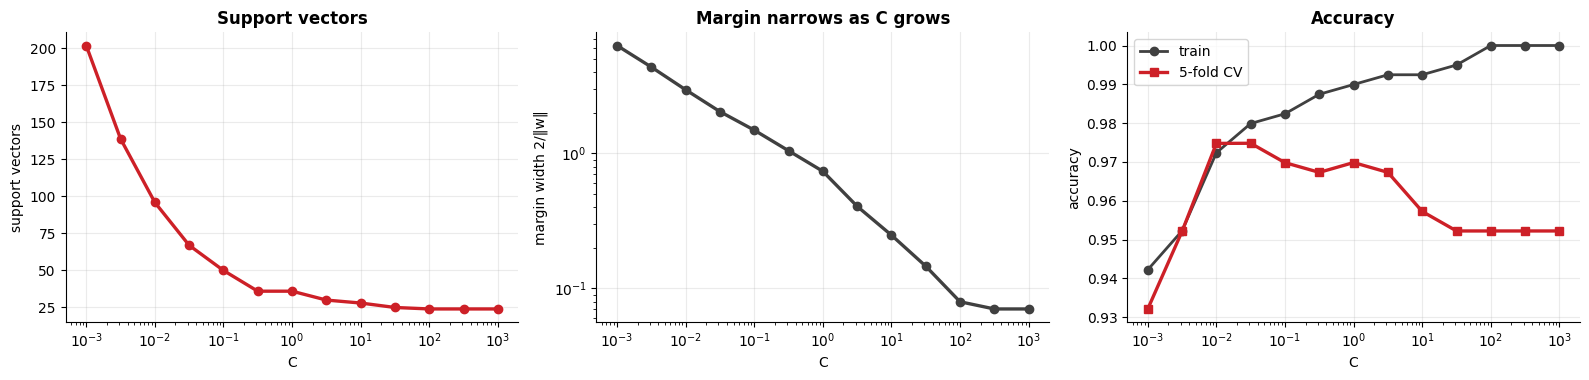

,C,support vectors,margin width,train acc,CV acc
0,0.001,202,6.299,0.942,0.932
3,0.032,67,2.041,0.980,0.975
6,1.000,36,0.738,0.990,0.970
9,31.623,25,0.146,0.995,0.952
12,1000.000,24,0.071,1.000,0.952


In [6]:
#Effect of C ( Linear SVM, 30 Attributes ): Support Vectors, Margin Width, Train and Cross-Validated Accuracy
rows = []
for c_ in np.logspace(-3, 3, 13):
    m = SVC(kernel="linear", C=c_).fit(Xs_tr, ytr)
    rows.append({"C": c_, "support vectors": len(m.support_), "margin width": 2 / np.linalg.norm(m.coef_), "train acc": m.score(Xs_tr, ytr),
                 "CV acc": cross_val_score(SVC(kernel="linear", C=c_), Xs_tr, ytr, cv=cv5).mean()})
cdf = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.9))
axes[0].plot(cdf["C"], cdf["support vectors"], marker="o", color=RED, lw=2.4); axes[0].set_xscale("log"); axes[0].set_xlabel("C"); axes[0].set_ylabel("support vectors"); axes[0].set_title("Support vectors")
axes[1].plot(cdf["C"], cdf["margin width"], marker="o", color=DARK, lw=2.4); axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("C"); axes[1].set_ylabel("margin width 2/‖w‖"); axes[1].set_title("Margin narrows as C grows")
axes[2].plot(cdf["C"], cdf["train acc"], marker="o", color=DARK, lw=2, label="train"); axes[2].plot(cdf["C"], cdf["CV acc"], marker="s", color=RED, lw=2.4, label="5-fold CV"); axes[2].set_xscale("log"); axes[2].set_xlabel("C"); axes[2].set_ylabel("accuracy"); axes[2].set_title("Accuracy"); axes[2].legend()
plt.tight_layout(); plt.show()
cdf.iloc[::3].round(3)

,CV ROC AUC,CV accuracy,support vectors
kernel,,,
linear,0.989,0.970,36
poly (deg 3),0.994,0.897,134
rbf,0.993,0.975,100
sigmoid,0.982,0.957,58


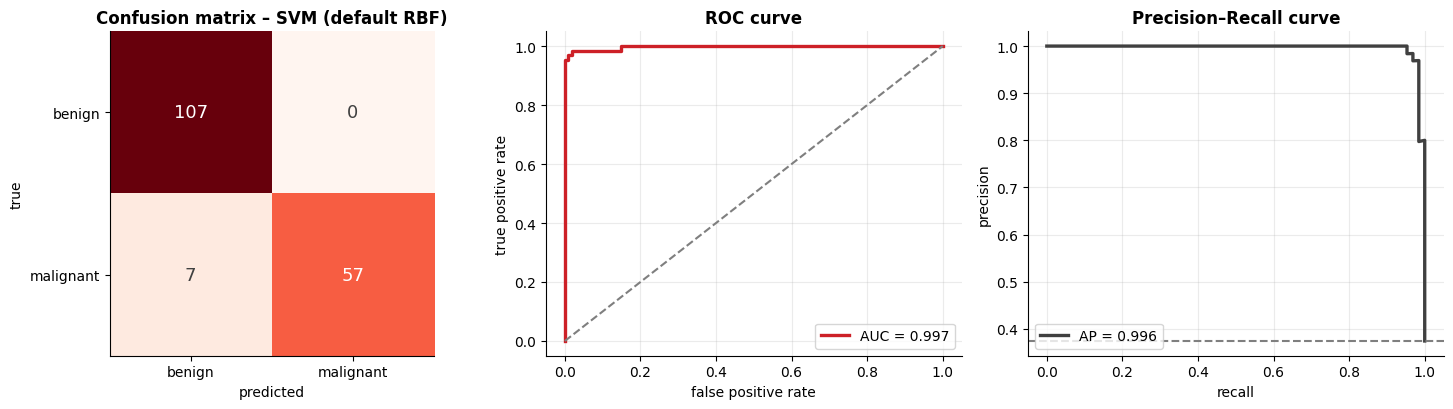

support vectors: 100 of 398 (25%) | per class: {'benign': 49, 'malignant': 51}


,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
SVM (default RBF),0.959,0.945,1.0,0.891,0.942,0.914,0.997,0.996


In [7]:
#Kernel Comparison ( 5-Fold CV on the Training Set ) and Evaluation of the Default RBF SVM on the Test Set
kernels = {"linear": SVC(kernel="linear"), "poly (deg 3)": SVC(kernel="poly", degree=3), "rbf": SVC(kernel="rbf"), "sigmoid": SVC(kernel="sigmoid")}
rows = []
for name, m in kernels.items():
    rows.append({"kernel": name, "CV ROC AUC": cross_val_score(m, Xs_tr, ytr, cv=cv5, scoring="roc_auc").mean(), "CV accuracy": cross_val_score(m, Xs_tr, ytr, cv=cv5).mean(), "support vectors": len(m.fit(Xs_tr, ytr).support_)})
kdf = pd.DataFrame(rows).set_index("kernel")
display(kdf.round(3))

svm = SVC(kernel="rbf", C=1.0, gamma="scale").fit(Xs_tr, ytr)
results["SVM (default RBF)"] = report_binary(yte, svm.predict(Xs_te), svm.decision_function(Xs_te), "SVM (default RBF)", CLASSES)
print(f"support vectors: {len(svm.support_)} of {len(ytr)} ({len(svm.support_) / len(ytr):.0%}) | per class: {dict(zip(CLASSES, map(int, svm.n_support_)))}")
results["SVM (default RBF)"].to_frame().T

### **3. Genetic Algorithm (GA)**

Evolves a **population**: evaluate the **fitness**, **select** parents (tournament of 3), **crossover** (uniform) and **mutate** (bit flips), keeping the best individuals (**elitism**).

**Problem:** *feature selection*. A chromosome has 30 bits (1 = use the attribute). **Fitness** = 5-fold CV accuracy of a logistic regression on the **training set** − 0.02 × (fraction of attributes used). The **test set is used only at the end**.

In [8]:
#Genetic Algorithm for Feature Selection ( Tournament Selection, Uniform Crossover, Bit-Flip Mutation, Elitism )
def make_fitness(Xtr, ytr, penalty=0.02):
    cache = {}
    def fitness(mask):
        key = mask.tobytes()
        if key not in cache:
            cols = np.flatnonzero(mask)
            acc = cross_val_score(LogisticRegression(max_iter=5000), Xtr[:, cols], ytr, cv=cv5).mean() if len(cols) else 0.0
            cache[key] = acc - penalty * len(cols) / Xtr.shape[1]
        return cache[key]
    return fitness, cache

def genetic_algorithm(fitness, n_genes, pop_size=24, generations=25, p_cross=0.9, p_mut=None, elite=2, seed=0):
    rng = np.random.default_rng(seed)
    p_mut = p_mut or 1 / n_genes
    pop = (rng.random((pop_size, n_genes)) < 0.3).astype(int)                                  # random initial population
    hist = {"best": [], "mean": [], "worst": [], "diversity": [], "size": []}
    for gen in range(generations):
        fit = np.array([fitness(ind) for ind in pop])
        hist["best"].append(fit.max()); hist["mean"].append(fit.mean()); hist["worst"].append(fit.min()); hist["size"].append(int(pop[fit.argmax()].sum()))
        hist["diversity"].append(np.mean([np.abs(pop[i] - pop[j]).sum() for i in range(pop_size) for j in range(i + 1, pop_size)]))   # mean Hamming distance
        order = np.argsort(-fit)
        new = [pop[i].copy() for i in order[:elite]]                                           # elitism
        while len(new) < pop_size:
            parents = []
            for _ in range(2):                                                                 # tournament selection (size 3)
                cand = rng.choice(pop_size, 3, replace=False); parents.append(pop[cand[fit[cand].argmax()]])
            child = np.where(rng.random(n_genes) < 0.5, parents[0], parents[1]) if rng.random() < p_cross else parents[0].copy()          # uniform crossover
            flip = rng.random(n_genes) < p_mut                                                 # bit-flip mutation
            new.append(np.where(flip, 1 - child, child))
        pop = np.array(new)
    fit = np.array([fitness(ind) for ind in pop])
    best = pop[fit.argmax()]
    return best, hist

fitness, cache = make_fitness(Xs_tr, ytr)
t0 = time.perf_counter()
best_mask, hist = genetic_algorithm(fitness, 30, seed=RANDOM_STATE)
print(f"best chromosome: {int(best_mask.sum())} attributes | fitness {fitness(best_mask):.4f} | CV accuracy {fitness(best_mask) + 0.02 * best_mask.sum() / 30:.4f} | unique evaluations: {len(cache)} | {time.perf_counter() - t0:.1f}s")
print("selected:", [names[i] for i in np.flatnonzero(best_mask)])

best chromosome: 13 attributes | fitness 0.9762 | CV accuracy 0.9849 | unique evaluations: 418 | 5.6s
selected: ['mean concavity', 'radius error', 'texture error', 'perimeter error', 'smoothness error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst concavity', 'worst symmetry']


#### **GA-Specific Metrics**

**Convergence** (best / mean / worst fitness per generation), **diversity** (mean Hamming distance – when it collapses the population has *converged prematurely*) and the **size** of the best subset.

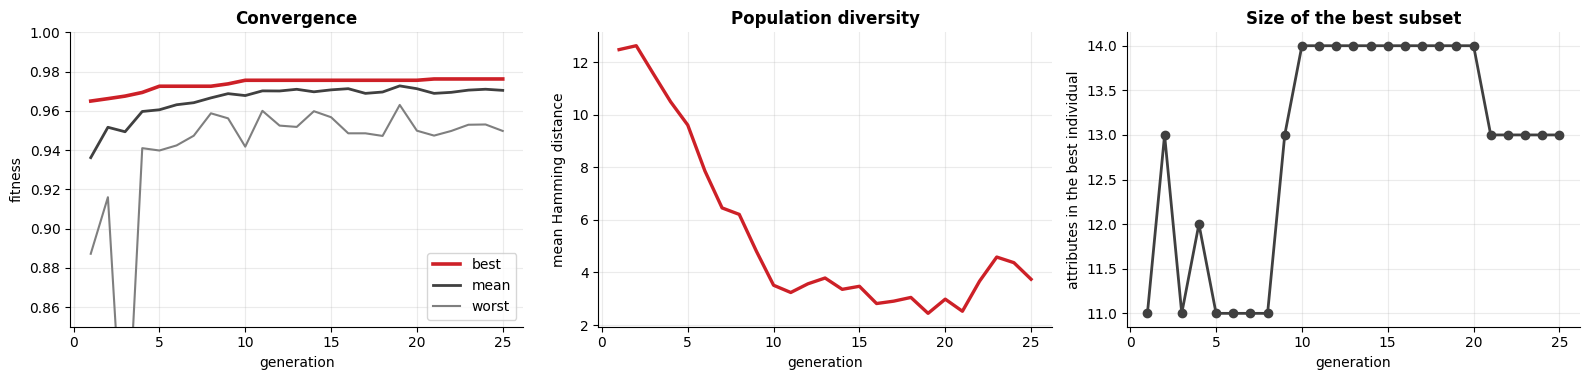

In [9]:
#Convergence, Population Diversity and Size of the Best Subset
fig, axes = plt.subplots(1, 3, figsize=(16, 3.9))
g = np.arange(1, len(hist["best"]) + 1)
axes[0].plot(g, hist["best"], color=RED, lw=2.6, label="best"); axes[0].plot(g, hist["mean"], color=DARK, lw=2, label="mean"); axes[0].plot(g, hist["worst"], color=GRAY, lw=1.5, label="worst")
axes[0].set_ylim(0.85, 1.0); axes[0].set_xlabel("generation"); axes[0].set_ylabel("fitness"); axes[0].set_title("Convergence"); axes[0].legend()
axes[1].plot(g, hist["diversity"], color=RED, lw=2.4); axes[1].set_xlabel("generation"); axes[1].set_ylabel("mean Hamming distance"); axes[1].set_title("Population diversity")
axes[2].plot(g, hist["size"], marker="o", color=DARK, lw=2); axes[2].set_xlabel("generation"); axes[2].set_ylabel("attributes in the best individual"); axes[2].set_title("Size of the best subset")
plt.tight_layout(); plt.show()

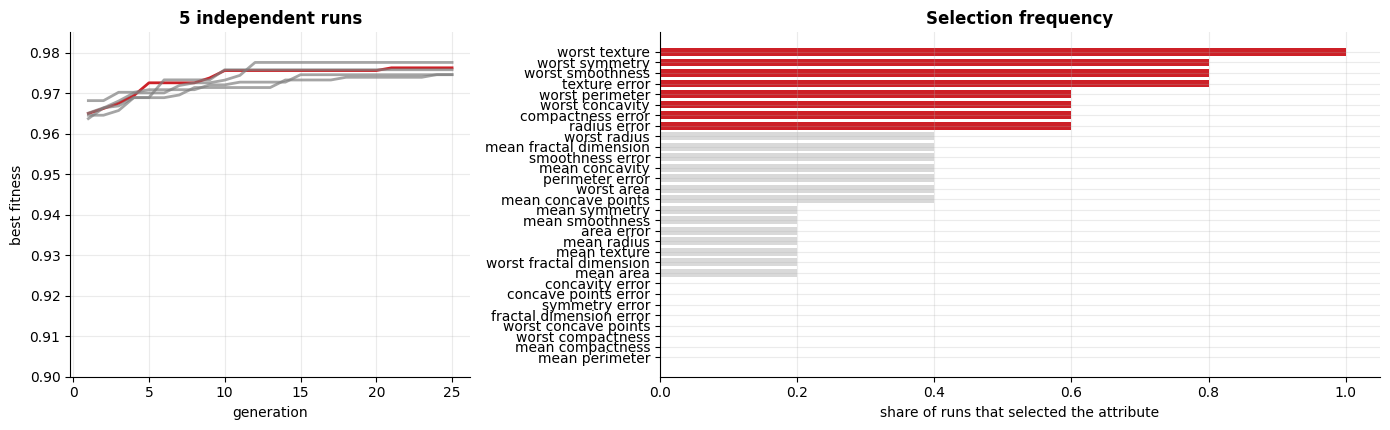

final fitness: mean 0.9757 ± 0.0011 | subset size: [13, 8, 10, 11, 8] | attributes selected by ≥ 60% of the runs: 8


In [10]:
#Stability Across 5 Independent Runs: Fitness, Subset Size and How Often Each Attribute Is Selected
runs = [(best_mask, hist)] + [genetic_algorithm(make_fitness(Xs_tr, ytr)[0], 30, seed=s) for s in range(1, 5)]
final_fit = [h["best"][-1] for _, h in runs]; sizes = [int(m.sum()) for m, _ in runs]
freq = np.mean([m for m, _ in runs], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1.8]})
for k, (_, h) in enumerate(runs):
    axes[0].plot(np.arange(1, len(h["best"]) + 1), h["best"], lw=2, color=RED if k == 0 else GRAY, alpha=1 if k == 0 else 0.7)
axes[0].set_ylim(0.9, 0.985); axes[0].set_xlabel("generation"); axes[0].set_ylabel("best fitness"); axes[0].set_title("5 independent runs")
order = np.argsort(freq)
axes[1].barh(np.array(names)[order], freq[order], color=[RED if f >= 0.6 else LIGHT for f in freq[order]], height=0.75); axes[1].set_xlabel("share of runs that selected the attribute"); axes[1].set_title("Selection frequency")
plt.tight_layout(); plt.show()
print(f"final fitness: mean {np.mean(final_fit):.4f} ± {np.std(final_fit):.4f} | subset size: {sizes} | attributes selected by ≥ 60% of the runs: {int((freq >= 0.6).sum())}")

,attributes,CV accuracy (train),test accuracy,test ROC AUC,test F1
selection,,,,,
all 30 attributes,30,0.985,0.971,0.998,0.960
GA (13),13,0.985,0.965,0.998,0.951
SelectKBest (13),13,0.932,0.977,1.000,0.968
RFE (13),13,0.967,0.982,0.999,0.976


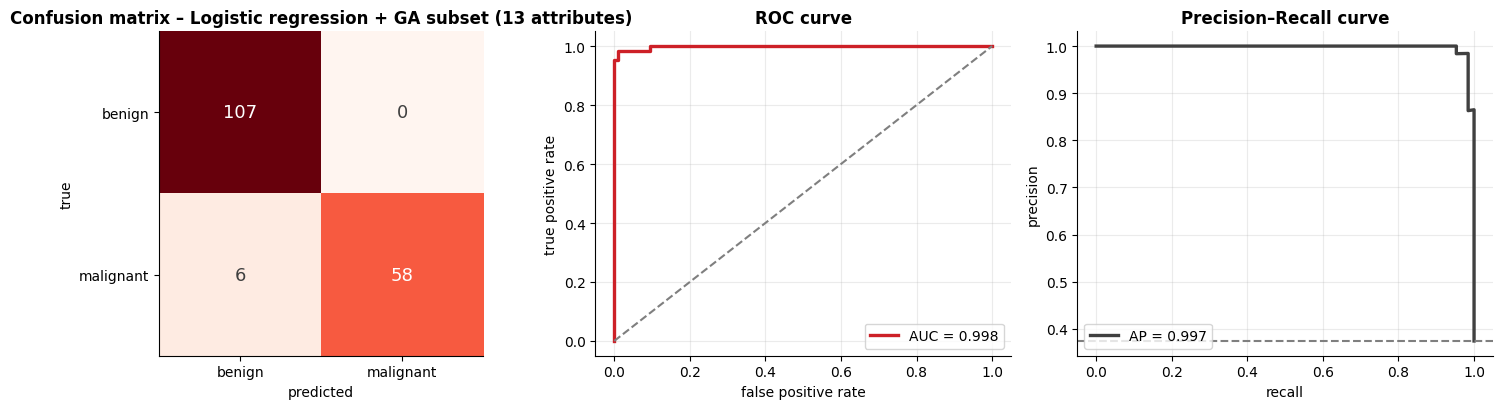

In [11]:
#Evaluate the GA-Selected Model on the Test Set and Compare with All Attributes, SelectKBest and RFE ( Same Subset Size )
from sklearn.feature_selection import SelectKBest, f_classif, RFE

cols_ga = np.flatnonzero(best_mask); k = len(cols_ga)
lr = lambda: LogisticRegression(max_iter=5000)
cols_kb = np.flatnonzero(SelectKBest(f_classif, k=k).fit(Xs_tr, ytr).get_support())
cols_rfe = np.flatnonzero(RFE(lr(), n_features_to_select=k).fit(Xs_tr, ytr).get_support())
rows = []
for name, cols in [("all 30 attributes", np.arange(30)), (f"GA ({k})", cols_ga), (f"SelectKBest ({k})", cols_kb), (f"RFE ({k})", cols_rfe)]:
    m = lr().fit(Xs_tr[:, cols], ytr); p = m.predict_proba(Xs_te[:, cols])[:, 1]
    rows.append({"selection": name, "attributes": len(cols), "CV accuracy (train)": cross_val_score(lr(), Xs_tr[:, cols], ytr, cv=cv5).mean(), "test accuracy": accuracy_score(yte, m.predict(Xs_te[:, cols])),
                 "test ROC AUC": roc_auc_score(yte, p), "test F1": f1_score(yte, m.predict(Xs_te[:, cols]))})
cmp_ga = pd.DataFrame(rows).set_index("selection")
display(cmp_ga.round(3))
m_ga = lr().fit(Xs_tr[:, cols_ga], ytr)
results["Logistic regression + GA subset"] = report_binary(yte, m_ga.predict(Xs_te[:, cols_ga]), m_ga.predict_proba(Xs_te[:, cols_ga])[:, 1], f"Logistic regression + GA subset ({k} attributes)", CLASSES)

On the test set the GA subset (13 of 30 attributes) is **on par** with all attributes, SelectKBest and RFE: the differences are **1–3 cases out of 171**, i.e. noise. The GA's value here is a **compact** subset found by a **gradient-free** search; its CV score is also slightly **optimistic**, because the same folds guided the search.

### **4. Particle Swarm Optimization (PSO)**

Each **particle** has a position $x$ and a velocity $v$ in the search space. At each iteration:

$$v \leftarrow w\,v + c_1 r_1 (p_{\text{best}} - x) + c_2 r_2 (g_{\text{best}} - x) \qquad x \leftarrow x + v$$

* $w$ = **inertia** · $c_1$ = **cognitive** pull (own best) · $c_2$ = **social** pull (swarm best)

**Problem:** tune $(\log_{10} C,\ \log_{10} \gamma)$ of the SVM by maximising the **5-fold CV ROC AUC** (training set).

In [12]:
#PSO Implementation and the Objective ( 5-Fold CV ROC AUC of an RBF SVM )
def svm_objective(v):
    return cross_val_score(SVC(kernel="rbf", C=10 ** v[0], gamma=10 ** v[1]), Xs_tr, ytr, cv=cv5, scoring="roc_auc").mean()

BOUNDS = np.array([[-2.0, 3.0], [-5.0, 0.0]])                                                  # log10(C) in [1e-2, 1e3], log10(gamma) in [1e-5, 1]

def pso(obj, bounds, n_particles=15, iters=15, w=0.7, c1=1.5, c2=1.5, seed=0):
    rng = np.random.default_rng(seed)
    lo, hi = bounds[:, 0], bounds[:, 1]
    pos = rng.uniform(lo, hi, (n_particles, len(lo))); vel = rng.uniform(-(hi - lo), hi - lo, pos.shape) * 0.1
    pbest, pbest_f = pos.copy(), np.array([obj(p) for p in pos])
    g = pbest_f.argmax(); gbest, gbest_f = pbest[g].copy(), pbest_f[g]
    hist = {"pos": [pos.copy()], "gbest": [gbest_f], "mean": [pbest_f.mean()], "diversity": [np.linalg.norm(pos - gbest, axis=1).mean()], "evals": [n_particles]}
    for it in range(iters):
        r1, r2 = rng.random(pos.shape), rng.random(pos.shape)
        vel = w * vel + c1 * r1 * (pbest - pos) + c2 * r2 * (gbest - pos)
        pos = np.clip(pos + vel, lo, hi)
        f = np.array([obj(p) for p in pos])
        better = f > pbest_f
        pbest[better], pbest_f[better] = pos[better], f[better]
        if pbest_f.max() > gbest_f:
            g = pbest_f.argmax(); gbest, gbest_f = pbest[g].copy(), pbest_f[g]
        hist["pos"].append(pos.copy()); hist["gbest"].append(gbest_f); hist["mean"].append(f.mean()); hist["diversity"].append(np.linalg.norm(pos - gbest, axis=1).mean()); hist["evals"].append(hist["evals"][-1] + n_particles)
    return gbest, gbest_f, hist

t0 = time.perf_counter()
gbest, gbest_f, ph = pso(svm_objective, BOUNDS, seed=RANDOM_STATE)
print(f"best: C = {10 ** gbest[0]:.3g}, gamma = {10 ** gbest[1]:.3g} | CV ROC AUC = {gbest_f:.4f} | evaluations: {ph['evals'][-1]} | {time.perf_counter() - t0:.1f}s")

best: C = 19, gamma = 0.0032 | CV ROC AUC = 0.9960 | evaluations: 240 | 4.6s


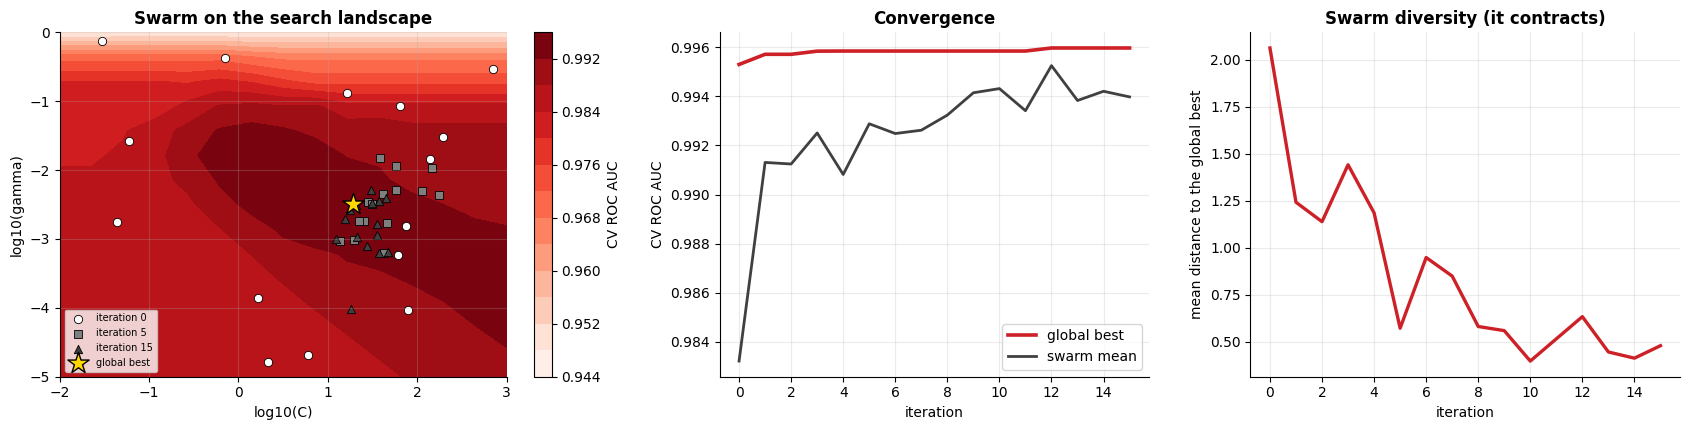

landscape maximum on the grid: 0.9958 | PSO found 0.9960


In [13]:
#The Search Landscape ( 15 x 15 Grid ) with the Swarm Trajectory, and PSO-Specific Convergence and Diversity
gc, gg = np.linspace(*BOUNDS[0], 15), np.linspace(*BOUNDS[1], 15)
land = np.array([[svm_objective([c_, g_]) for c_ in gc] for g_ in gg])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={"width_ratios": [1.3, 1, 1]})
cs = axes[0].contourf(gc, gg, land, levels=14, cmap="Reds"); fig.colorbar(cs, ax=axes[0], label="CV ROC AUC")
for it, marker, color in [(0, "o", "white"), (5, "s", GRAY), (len(ph["pos"]) - 1, "^", DARK)]:
    axes[0].scatter(*ph["pos"][it].T, s=36, marker=marker, color=color, edgecolor="black", lw=0.6, label=f"iteration {it}")
axes[0].scatter(*gbest, marker="*", s=260, color="gold", edgecolor="black", label="global best"); axes[0].set_xlabel("log10(C)"); axes[0].set_ylabel("log10(gamma)"); axes[0].set_title("Swarm on the search landscape"); axes[0].legend(fontsize=7, loc="lower left")
it = np.arange(len(ph["gbest"]))
axes[1].plot(it, ph["gbest"], color=RED, lw=2.6, label="global best"); axes[1].plot(it, ph["mean"], color=DARK, lw=2, label="swarm mean"); axes[1].set_xlabel("iteration"); axes[1].set_ylabel("CV ROC AUC"); axes[1].set_title("Convergence"); axes[1].legend()
axes[2].plot(it, ph["diversity"], color=RED, lw=2.4); axes[2].set_xlabel("iteration"); axes[2].set_ylabel("mean distance to the global best"); axes[2].set_title("Swarm diversity (it contracts)")
plt.tight_layout(); plt.show()
print(f"landscape maximum on the grid: {land.max():.4f} | PSO found {gbest_f:.4f}")

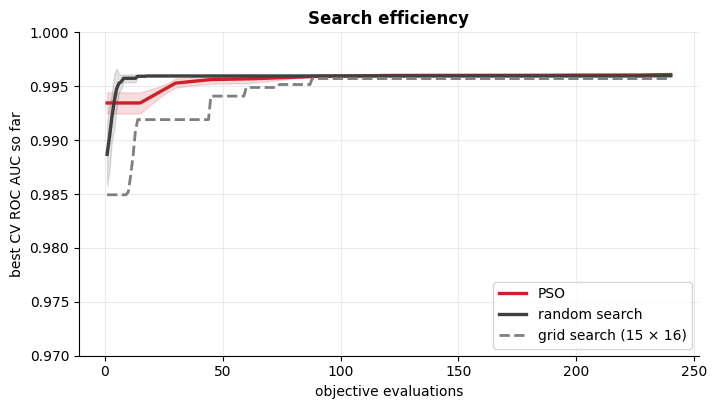

after 240 evaluations → PSO 0.9961 ± 0.0001 | random 0.9960 ± 0.0001 | grid 0.9957


In [14]:
#PSO vs Random Search vs Grid Search with the Same Budget ( 240 Evaluations ): Best Score so Far, 5 Seeds
budget = 240
pso_curves, rnd_curves = [], []
for seed in range(5):
    _, _, h = pso(svm_objective, BOUNDS, seed=seed)
    pso_curves.append(np.interp(np.arange(1, budget + 1), h["evals"], h["gbest"]))
    rng = np.random.default_rng(100 + seed)
    vals = [svm_objective(rng.uniform(BOUNDS[:, 0], BOUNDS[:, 1])) for _ in range(budget)]
    rnd_curves.append(np.maximum.accumulate(vals))
gs = np.array([[svm_objective([c_, g_]) for c_ in np.linspace(*BOUNDS[0], 15)] for g_ in np.linspace(*BOUNDS[1], 16)]).ravel()
grid_curve = np.maximum.accumulate(gs)

plt.figure(figsize=(8, 4.2))
for curves, color, name in [(pso_curves, RED, "PSO"), (rnd_curves, DARK, "random search")]:
    mean, sd = np.mean(curves, axis=0), np.std(curves, axis=0)
    plt.plot(np.arange(1, budget + 1), mean, color=color, lw=2.4, label=name); plt.fill_between(np.arange(1, budget + 1), mean - sd, mean + sd, color=color, alpha=0.15)
plt.plot(np.arange(1, budget + 1), grid_curve, color=GRAY, lw=2, ls="--", label="grid search (15 × 16)")
plt.xlabel("objective evaluations"); plt.ylabel("best CV ROC AUC so far"); plt.ylim(0.97, 1.0); plt.title("Search efficiency"); plt.legend(loc="lower right")
plt.show()
print(f"after {budget} evaluations → PSO {np.mean([c[-1] for c in pso_curves]):.4f} ± {np.std([c[-1] for c in pso_curves]):.4f} | random {np.mean([c[-1] for c in rnd_curves]):.4f} ± {np.std([c[-1] for c in rnd_curves]):.4f} | grid {grid_curve[-1]:.4f}")

In this **2-D, smooth** landscape the three searches reach the **same plateau** (differences ≈ 10⁻⁴): PSO has **no real advantage** here. Swarms pay off with **many parameters** or **rugged** landscapes, where a grid becomes impossible.

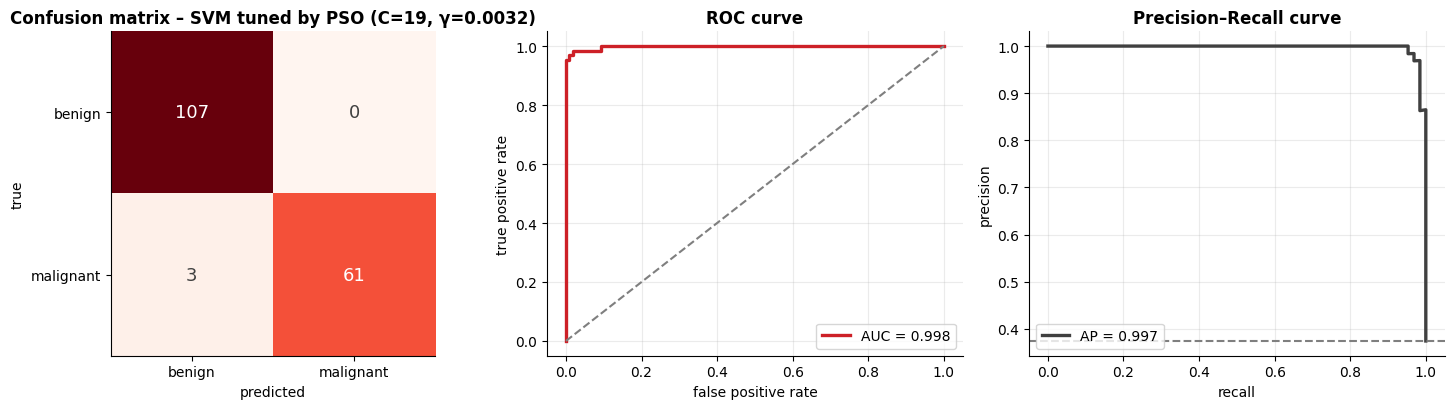

,accuracy,recall,precision,F1,ROC AUC,PR AUC
default SVM,0.959,0.891,1.0,0.942,0.997,0.996
PSO-tuned SVM,0.982,0.953,1.0,0.976,0.998,0.997


In [15]:
#Evaluate the PSO-Tuned SVM on the Test Set and Compare with the Default SVM
svm_pso = SVC(kernel="rbf", C=10 ** gbest[0], gamma=10 ** gbest[1]).fit(Xs_tr, ytr)
results["SVM (PSO-tuned)"] = report_binary(yte, svm_pso.predict(Xs_te), svm_pso.decision_function(Xs_te), f"SVM tuned by PSO (C={10 ** gbest[0]:.2g}, γ={10 ** gbest[1]:.2g})", CLASSES)
pd.DataFrame({"default SVM": results["SVM (default RBF)"], "PSO-tuned SVM": results["SVM (PSO-tuned)"]}).T[["accuracy", "recall", "precision", "F1", "ROC AUC", "PR AUC"]].round(3)

### **5. Simulated Annealing (SA)**

Inspired by the **slow cooling of metals**: propose a **neighbour**; accept it if better, or if **worse by $\Delta$** with probability $e^{-\Delta/T}$. A **high** temperature explores, a **low** one exploits, and the search can escape **local optima**.

**Problem:** the **Travelling Salesman Problem** (40 random cities) with **2-opt moves**. The quality measure is the **tour length** (no classification metrics apply).

In [16]:
#TSP Instance, Baselines ( Random Tour, Nearest Neighbour, 2-opt Local Search ) and Simulated Annealing
from scipy.spatial.distance import squareform, pdist

rng = np.random.default_rng(RANDOM_STATE)
cities = rng.random((40, 2))
D = squareform(pdist(cities))
n_c = len(cities)
tour_len = lambda t: D[t, np.roll(t, -1)].sum()

def nearest_neighbour(start=0):
    tour, left = [start], set(range(n_c)) - {start}
    while left:
        nxt = min(left, key=lambda j: D[tour[-1], j]); tour.append(nxt); left.remove(nxt)
    return np.array(tour)

def two_opt_delta(t, i, j):                                                                    # change of length when reversing t[i..j]
    a, b, c, d = t[i - 1], t[i], t[j], t[(j + 1) % n_c]
    return D[a, c] + D[b, d] - D[a, b] - D[c, d]

def two_opt_local_search(t):
    t, improved = t.copy(), True
    while improved:
        improved = False
        for i in range(1, n_c - 1):
            for j in range(i + 1, n_c):
                if two_opt_delta(t, i, j) < -1e-12:
                    t[i:j + 1] = t[i:j + 1][::-1]; improved = True
    return t

def simulated_annealing(iters=40000, T0=0.5, T_end=0.002, seed=0, start=None):
    rng = np.random.default_rng(seed)
    t = rng.permutation(n_c) if start is None else start.copy()
    cur, best, best_t = tour_len(t), tour_len(t), t.copy()
    hist = {"current": [], "best": [], "T": [], "accepted": []}
    for it in range(iters):
        T = T0 * (T_end / T0) ** (it / iters)                                                 # geometric cooling
        i, j = np.sort(rng.choice(np.arange(1, n_c), 2, replace=False))
        delta = two_opt_delta(t, i, j)
        accept = delta < 0 or (T > 0 and rng.random() < np.exp(-delta / T))
        if accept:
            t[i:j + 1] = t[i:j + 1][::-1]; cur += delta
            if cur < best - 1e-12:
                best, best_t = cur, t.copy()
        hist["current"].append(cur); hist["best"].append(best); hist["T"].append(T); hist["accepted"].append(accept)
    return best_t, best, hist

random_len = np.mean([tour_len(np.random.default_rng(s).permutation(n_c)) for s in range(500)])
nn_t = nearest_neighbour(); nn_len = tour_len(nn_t)
nn2_t = two_opt_local_search(nn_t); nn2_len = tour_len(nn2_t)
sa_t, sa_len, sa_h = simulated_annealing(seed=RANDOM_STATE)
print(f"random tour (mean of 500): {random_len:.2f} | nearest neighbour: {nn_len:.2f} | NN + 2-opt: {nn2_len:.2f} | simulated annealing: {sa_len:.2f}")

random tour (mean of 500): 19.91 | nearest neighbour: 5.71 | NN + 2-opt: 5.16 | simulated annealing: 5.26


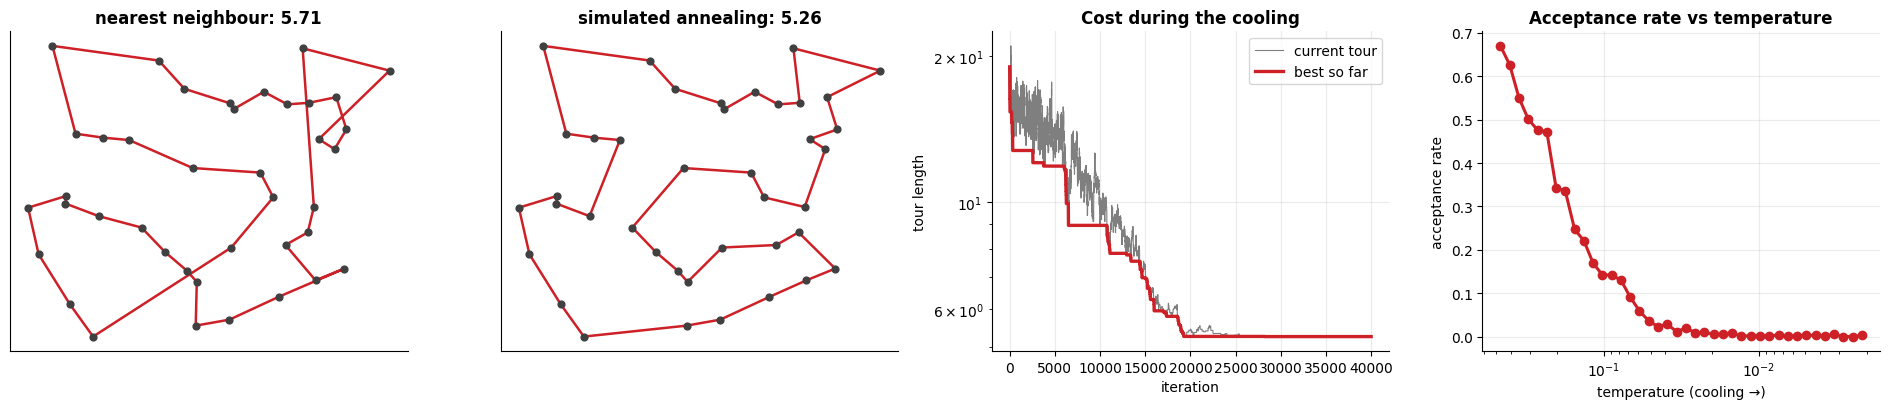

In [17]:
#SA-Specific Metrics: Tours, Cost Along the Cooling, and Acceptance Rate per Temperature
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for ax, (title, t) in zip(axes[:2], [("nearest neighbour", nn_t), ("simulated annealing", sa_t)]):
    closed = np.r_[t, t[0]]
    ax.plot(cities[closed, 0], cities[closed, 1], color=RED, lw=1.8); ax.scatter(*cities.T, s=24, color=DARK, zorder=3); ax.set_title(f"{title}: {tour_len(t):.2f}"); ax.set_xticks([]); ax.set_yticks([])
it = np.arange(len(sa_h["current"]))
axes[2].plot(it, sa_h["current"], color=GRAY, lw=0.8, label="current tour"); axes[2].plot(it, sa_h["best"], color=RED, lw=2.4, label="best so far"); axes[2].set_yscale("log"); axes[2].set_xlabel("iteration"); axes[2].set_ylabel("tour length"); axes[2].set_title("Cost during the cooling"); axes[2].legend()
win = 1000
acc_rate = np.array(sa_h["accepted"]).reshape(-1, win).mean(axis=1); T_win = np.array(sa_h["T"]).reshape(-1, win).mean(axis=1)
axes[3].plot(T_win, acc_rate, marker="o", color=RED, lw=2.2); axes[3].set_xscale("log"); axes[3].invert_xaxis(); axes[3].set_xlabel("temperature (cooling →)"); axes[3].set_ylabel("acceptance rate"); axes[3].set_title("Acceptance rate vs temperature")
plt.tight_layout(); plt.show()

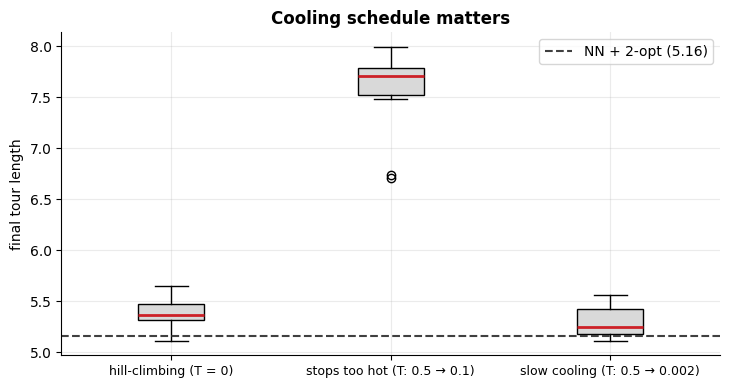

,mean,std,min
hill-climbing (T = 0),5.382,0.173,5.116
stops too hot (T: 0.5 → 0.1),7.532,0.448,6.706
slow cooling (T: 0.5 → 0.002),5.293,0.158,5.116


In [18]:
#Effect of the Cooling Schedule ( 10 Runs Each ): Final Tour Length of SA with Different Final Temperatures vs Hill-Climbing ( T = 0 )
schedules = {"hill-climbing (T = 0)": dict(T0=1e-9, T_end=1e-9), "stops too hot (T: 0.5 → 0.1)": dict(T0=0.5, T_end=0.1), "slow cooling (T: 0.5 → 0.002)": dict(T0=0.5, T_end=0.002)}
final = {name: [simulated_annealing(iters=20000, seed=s, **kw)[1] for s in range(10)] for name, kw in schedules.items()}
fig, ax = plt.subplots(figsize=(8.5, 4.2))
bp = ax.boxplot(list(final.values()), patch_artist=True, medianprops=dict(color=RED, lw=2))
for b in bp["boxes"]:
    b.set_facecolor(LIGHT)
ax.axhline(nn2_len, color=DARK, ls="--", label=f"NN + 2-opt ({nn2_len:.2f})"); ax.set_xticks(range(1, 4)); ax.set_xticklabels(list(final), fontsize=9); ax.set_ylabel("final tour length"); ax.set_title("Cooling schedule matters"); ax.legend()
plt.show()
pd.DataFrame({k: pd.Series(v).describe()[["mean", "std", "min"]] for k, v in final.items()}).T.round(3)

Stopping **while still hot** is the **worst** choice (the walk keeps accepting bad moves). With 40 cities and 2-opt moves the landscape is **easy**: plain hill-climbing is already close to slow annealing (≈ 5.38 vs 5.29) and both reach 5.116 in their best run. SA's edge grows with **problem size** and **ruggedness**.

### **6. Fuzzy Inference System (Mamdani)**

Handles **vagueness** with **linguistic variables** (*radius is high*) and **membership degrees** in $[0, 1]$:

1. **Fuzzification:** each measurement gets a degree for *low / medium / high*
2. **Rules** (IF–THEN) are evaluated: AND = **min**; the output set is **clipped** by the rule's firing strength
3. **Aggregation** of the rules (max) and **defuzzification** (centroid) → a crisp **risk score** in [0, 100]

Membership functions come from the **training-set percentiles** (25 / 50 / 75); the rules are illustrative, **not** clinical advice.

In [19]:
#Fuzzy System from Scratch ( Membership Functions, Rules, Min/Max Inference, Centroid Defuzzification )
def trap(x, a, b, c, d):
    """Trapezoidal membership (a = b: left shoulder, c = d: right shoulder)."""
    return np.clip(np.minimum((x - a) / (b - a + 1e-12), (d - x) / (d - c + 1e-12)), 0, 1)

FUZZY_VARS = {"radius": "mean radius", "concavity": "mean concave points", "texture": "mean texture"}
mfs = {}
for var, col in FUZZY_VARS.items():
    q25, q50, q75 = np.percentile(X_train[col], [25, 50, 75]); lo_, hi_ = X_train[col].min() - 1e-3, X_train[col].max() + 1e-3
    mfs[var] = {"low": (lo_, lo_, q25, q50), "medium": (q25, q50, q50, q75), "high": (q50, q75, hi_, hi_)}
risk_axis = np.linspace(0, 100, 201)
out_mf = {"low": trap(risk_axis, 0, 0, 20, 45), "medium": trap(risk_axis, 30, 50, 50, 70), "high": trap(risk_axis, 55, 80, 100, 100)}

RULES = [({"concavity": "high", "radius": "high"}, "high"), ({"concavity": "high", "radius": "medium"}, "high"), ({"concavity": "medium", "radius": "high"}, "high"),
         ({"concavity": "high", "radius": "low"}, "medium"), ({"concavity": "medium", "radius": "medium"}, "medium"), ({"concavity": "medium", "texture": "high"}, "medium"),
         ({"concavity": "low", "radius": "medium"}, "low"), ({"concavity": "low", "radius": "low"}, "low"), ({"concavity": "medium", "radius": "low"}, "low"), ({"concavity": "low", "texture": "low"}, "low")]

def fuzzy_infer(Xdf):
    """Returns the risk score of every row and the firing strength of every rule."""
    deg = {var: {term: trap(Xdf[col].to_numpy(), *params) for term, params in mfs[var].items()} for var, col in FUZZY_VARS.items()}
    fire = np.array([np.minimum.reduce([deg[v][t] for v, t in cond.items()]) for cond, _ in RULES]).T                  # AND = min  -> (N, rules)
    agg = np.zeros((len(Xdf), len(risk_axis)))
    for r, (_, out) in enumerate(RULES):
        agg = np.maximum(agg, np.minimum(fire[:, [r]], out_mf[out][None, :]))                                           # clip and aggregate (max)
    centroid = np.where(agg.sum(axis=1) > 1e-12, (agg * risk_axis).sum(axis=1) / np.maximum(agg.sum(axis=1), 1e-12), 50.0)  # centroid defuzzification
    return centroid, fire

risk_tr, _ = fuzzy_infer(X_train); risk_te, fire_te = fuzzy_infer(X_test)
print("rules:", len(RULES), "| risk score range on the test set:", round(float(risk_te.min()), 1), "to", round(float(risk_te.max()), 1))

rules: 10 | risk score range on the test set: 17.2 to 82.8


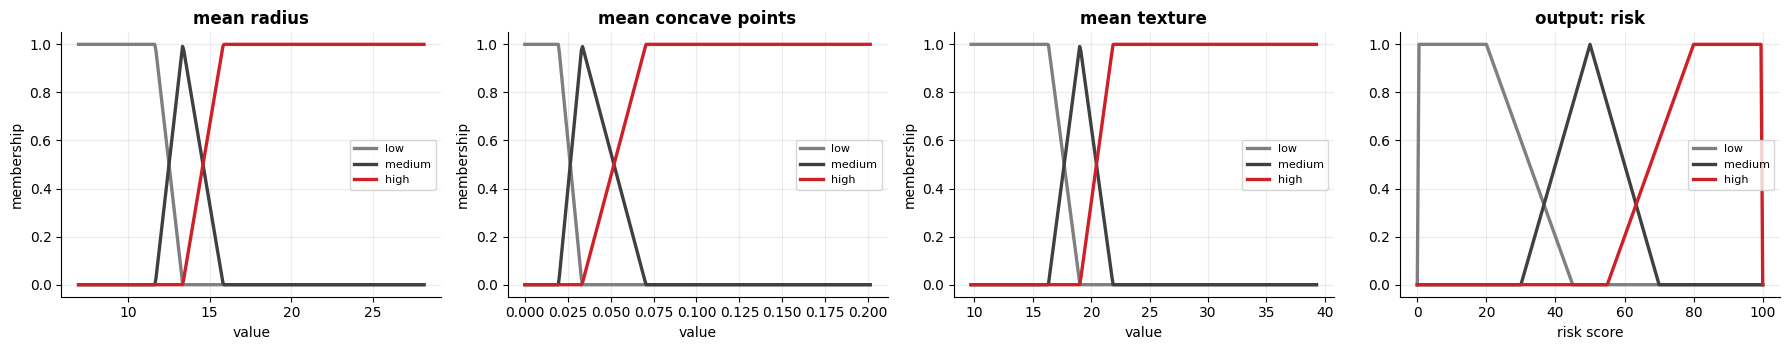

In [20]:
#Membership Functions of the Inputs and of the Output
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, (var, col) in zip(axes[:3], FUZZY_VARS.items()):
    xs = np.linspace(X_train[col].min(), X_train[col].max(), 300)
    for term, color in zip(["low", "medium", "high"], [GRAY, DARK, RED]):
        ax.plot(xs, trap(xs, *mfs[var][term]), color=color, lw=2.4, label=term)
    ax.set_title(col); ax.set_xlabel("value"); ax.set_ylabel("membership"); ax.legend(fontsize=8)
for term, color in zip(["low", "medium", "high"], [GRAY, DARK, RED]):
    axes[3].plot(risk_axis, out_mf[term], color=color, lw=2.4, label=term)
axes[3].set_title("output: risk"); axes[3].set_xlabel("risk score"); axes[3].legend(fontsize=8)
plt.tight_layout(); plt.show()

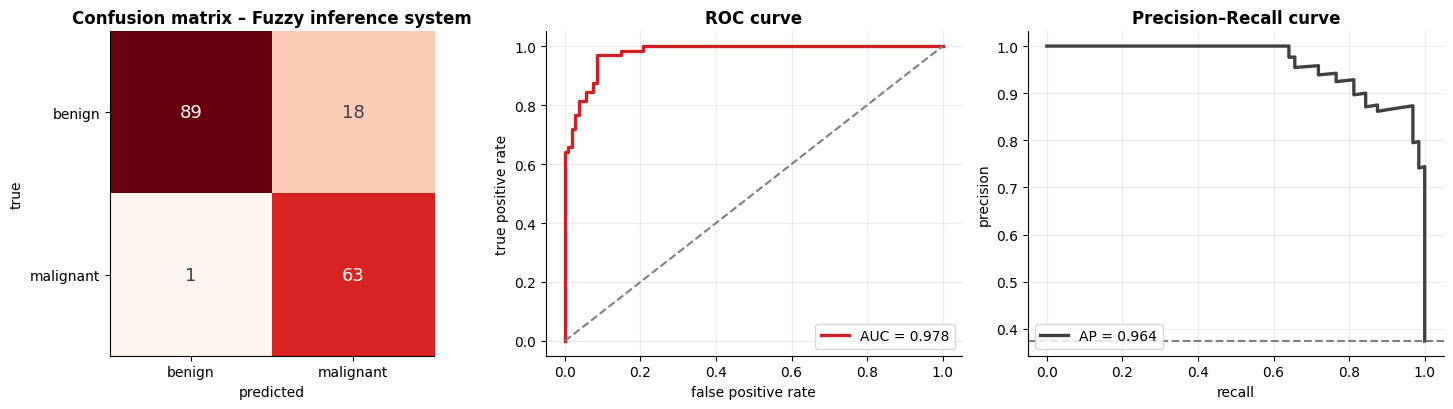

,accuracy,recall,precision,F1,ROC AUC,PR AUC
fuzzy system (10 rules),0.889,0.984,0.778,0.869,0.978,0.964
logistic regression (same 3 attributes),0.942,NaN,NaN,0.921,0.988,NaN


In [21]:
#Evaluate the Fuzzy System on the Test Set ( Threshold 50 ) and Compare with Logistic Regression on the Same 3 Attributes
results["Fuzzy system"] = report_binary(yte, (risk_te > 50).astype(int), risk_te, "Fuzzy inference system", CLASSES)
cols3 = list(FUZZY_VARS.values())
lr3 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(X_train[cols3], ytr)
p3 = lr3.predict_proba(X_test[cols3])[:, 1]
pd.DataFrame({"fuzzy system (10 rules)": results["Fuzzy system"], "logistic regression (same 3 attributes)": pd.Series({"accuracy": accuracy_score(yte, (p3 > 0.5).astype(int)), "ROC AUC": roc_auc_score(yte, p3), "F1": f1_score(yte, (p3 > 0.5).astype(int))})}).T[["accuracy", "recall", "precision", "F1", "ROC AUC", "PR AUC"]].round(3)

With **10 readable rules** the fuzzy system **ranks** the cases almost as well as logistic regression (AUC 0.978 vs 0.988). At the fixed threshold of 50 it favours **recall** (0.98) over **precision** (0.78): moving the threshold trades one for the other.

#### **Fuzzy-Specific Metrics and Visualisations**

How often each **rule fires**, the **coverage** (cases where at least one rule fires strongly) and the **control surface** (risk as a function of two inputs).

coverage: 100.0% of the test cases fire at least one rule with strength > 0.2 | mean number of active rules (strength > 0.2): 2.16


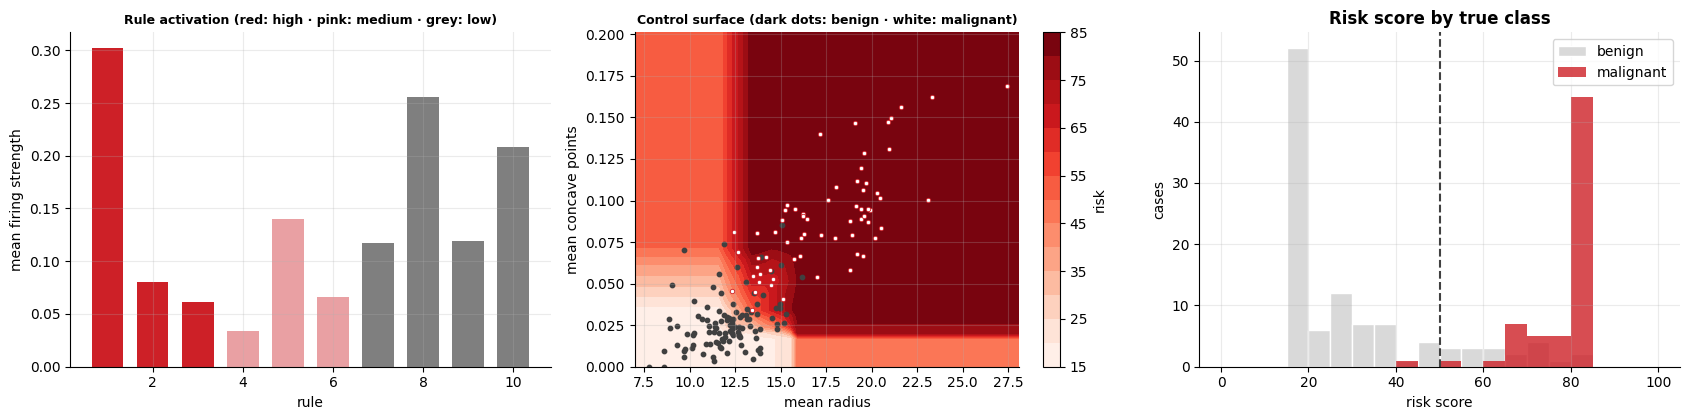

In [22]:
#Rule Activation, Coverage and the Control Surface ( Risk vs Concavity and Radius, Texture at the Median )
mean_fire = fire_te.mean(axis=0)
max_fire = fire_te.max(axis=1)
print(f"coverage: {(max_fire > 0.2).mean():.1%} of the test cases fire at least one rule with strength > 0.2 | mean number of active rules (strength > 0.2): {(fire_te > 0.2).sum(axis=1).mean():.2f}")

gr, gk = np.meshgrid(np.linspace(X_train["mean radius"].min(), X_train["mean radius"].max(), 60), np.linspace(X_train["mean concave points"].min(), X_train["mean concave points"].max(), 60))
surf_df = pd.DataFrame({"mean radius": gr.ravel(), "mean concave points": gk.ravel(), "mean texture": np.median(X_train["mean texture"])})
surface = fuzzy_infer(surf_df)[0].reshape(gr.shape)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
axes[0].bar(range(1, len(RULES) + 1), mean_fire, color=[RED if o == "high" else (SOFT if o == "medium" else GRAY) for _, o in RULES], width=0.7); axes[0].set_xlabel("rule"); axes[0].set_ylabel("mean firing strength"); axes[0].set_title("Rule activation (red: high · pink: medium · grey: low)", fontsize=9)
im = axes[1].contourf(gr, gk, surface, levels=15, cmap="Reds"); fig.colorbar(im, ax=axes[1], label="risk"); axes[1].scatter(X_test["mean radius"][yte == 0], X_test["mean concave points"][yte == 0], s=10, color=DARK); axes[1].scatter(X_test["mean radius"][yte == 1], X_test["mean concave points"][yte == 1], s=10, color="white", edgecolor=RED, lw=0.6)
axes[1].set_xlabel("mean radius"); axes[1].set_ylabel("mean concave points"); axes[1].set_title("Control surface (dark dots: benign · white: malignant)", fontsize=9)
axes[2].hist(risk_te[yte == 0], bins=20, range=(0, 100), color=LIGHT, edgecolor="white", label="benign"); axes[2].hist(risk_te[yte == 1], bins=20, range=(0, 100), color=RED, alpha=0.8, label="malignant"); axes[2].axvline(50, color=DARK, ls="--")
axes[2].set_xlabel("risk score"); axes[2].set_ylabel("cases"); axes[2].set_title("Risk score by true class"); axes[2].legend()
plt.tight_layout(); plt.show()

### **7. Isolation Forest (Anomaly Detection)**

Anomalies are **few and different**, so a **random** tree isolates them with **few splits**: the **path length** to isolate a point is short for anomalies. The anomaly score of $x$ is

$$s(x) = 2^{-E[h(x)] / c(\psi)} \qquad c(\psi) = 2\,(\ln(\psi - 1) + 0.5772) - \frac{2(\psi - 1)}{\psi}$$

($E[h]$ = mean path length over the trees, $\psi$ = sub-sample size). Score close to **1 = anomaly**, close to 0.5 or lower = normal.

**Setting (novelty detection):** train **only on benign** cases; the test set has all benign cases plus **12 malignant** ones (≈ 10 % anomalies).

In [23]:
#Isolation Forest from Scratch ( Random Trees, Path Length, Normalised Score ) and the Novelty-Detection Data
class IsolationForestScratch:
    def __init__(self, n_trees=100, max_samples=256, seed=0):
        self.n_trees, self.max_samples, self.seed = n_trees, max_samples, seed

    @staticmethod
    def c(n):
        return 0.0 if n <= 1 else (1.0 if n == 2 else 2 * (np.log(n - 1) + 0.5772156649) - 2 * (n - 1) / n)

    def _build(self, X, depth, limit, rng):
        if depth >= limit or len(X) <= 1:
            return {"size": len(X)}
        f = int(rng.integers(X.shape[1])); lo, hi = X[:, f].min(), X[:, f].max()
        if lo == hi:
            return {"size": len(X)}
        s = rng.uniform(lo, hi)
        m = X[:, f] < s
        return {"f": f, "s": s, "l": self._build(X[m], depth + 1, limit, rng), "r": self._build(X[~m], depth + 1, limit, rng)}

    def fit(self, X):
        rng = np.random.default_rng(self.seed)
        self.psi_ = min(self.max_samples, len(X)); limit = int(np.ceil(np.log2(self.psi_)))
        self.trees_ = [self._build(X[rng.choice(len(X), self.psi_, replace=False)], 0, limit, rng) for _ in range(self.n_trees)]
        return self

    def _depth(self, node, X, depth):
        if "size" in node:
            return np.full(len(X), depth + self.c(node["size"]))
        out, m = np.empty(len(X)), X[:, node["f"]] < node["s"]
        out[m] = self._depth(node["l"], X[m], depth + 1); out[~m] = self._depth(node["r"], X[~m], depth + 1)
        return out

    def mean_path(self, X):
        return np.mean([self._depth(t, X, 0) for t in self.trees_], axis=0)

    def score(self, X):
        return 2 ** (-self.mean_path(X) / self.c(self.psi_))

rng = np.random.default_rng(RANDOM_STATE)
normal_tr = Xs_tr[ytr == 0]                                                                    # training data: benign only
mal_idx = rng.choice(np.flatnonzero(yte == 1), 12, replace=False)
test_idx = np.r_[np.flatnonzero(yte == 0), mal_idx]
X_anom, y_anom = Xs_te[test_idx], yte[test_idx]
print("normal training cases:", len(normal_tr), "| test cases:", len(y_anom), "| anomalies in the test set:", int(y_anom.sum()), f"({y_anom.mean():.1%})")

iforest = IsolationForestScratch(n_trees=200, max_samples=128, seed=RANDOM_STATE).fit(normal_tr)
score_if = iforest.score(X_anom)
from sklearn.ensemble import IsolationForest
sk_if = IsolationForest(n_estimators=200, max_samples=128, random_state=RANDOM_STATE).fit(normal_tr)
from scipy.stats import spearmanr
print(f"ROC AUC: scratch {roc_auc_score(y_anom, score_if):.3f} | scikit-learn {roc_auc_score(y_anom, -sk_if.score_samples(X_anom)):.3f} | Spearman correlation between the two scores: {spearmanr(score_if, -sk_if.score_samples(X_anom))[0]:.3f}")

normal training cases: 250 | test cases: 119 | anomalies in the test set: 12 (10.1%)
ROC AUC: scratch 0.935 | scikit-learn 0.935 | Spearman correlation between the two scores: 0.976


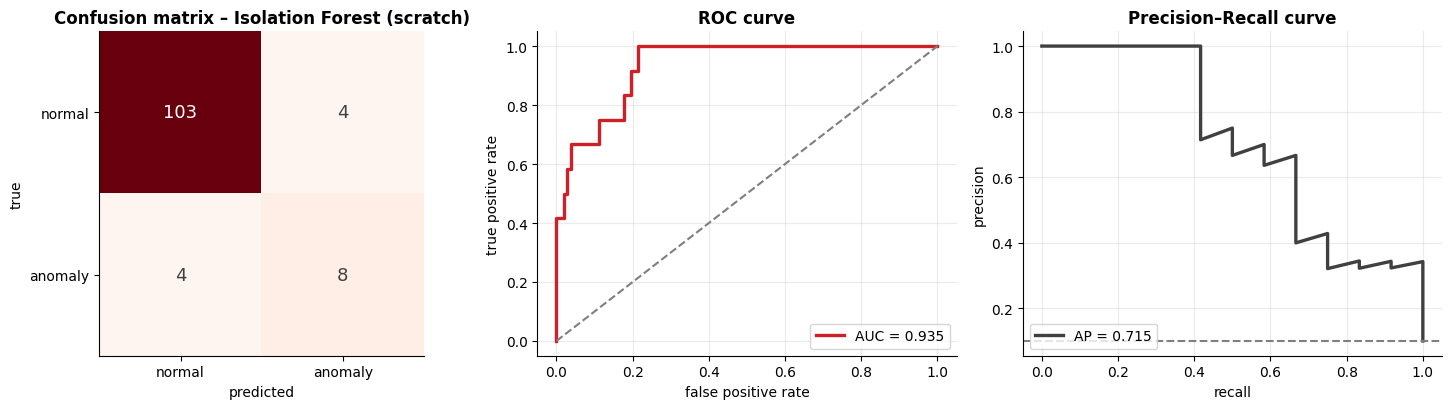

threshold: 0.550


,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
Isolation Forest (scratch),0.933,0.815,0.667,0.667,0.667,0.629,0.935,0.715


In [24]:
#Evaluate the Isolation Forest ( Threshold = 95th Percentile of the Training Scores ): Confusion Matrix, ROC and Precision-Recall
thr = np.quantile(iforest.score(normal_tr), 0.95)                                              # tolerate 5% false alarms on normal data
pred_if = (score_if > thr).astype(int)
results_anom = {}
results_anom["Isolation Forest (scratch)"] = report_binary(y_anom, pred_if, score_if, "Isolation Forest (scratch)", ["normal", "anomaly"])
print(f"threshold: {thr:.3f}")
results_anom["Isolation Forest (scratch)"].to_frame().T

#### **Isolation-Forest-Specific Metrics**

The **path length** (short for anomalies), the **score distribution**, and the effect of the **number of trees** and of the **sub-sample size** $\psi$.

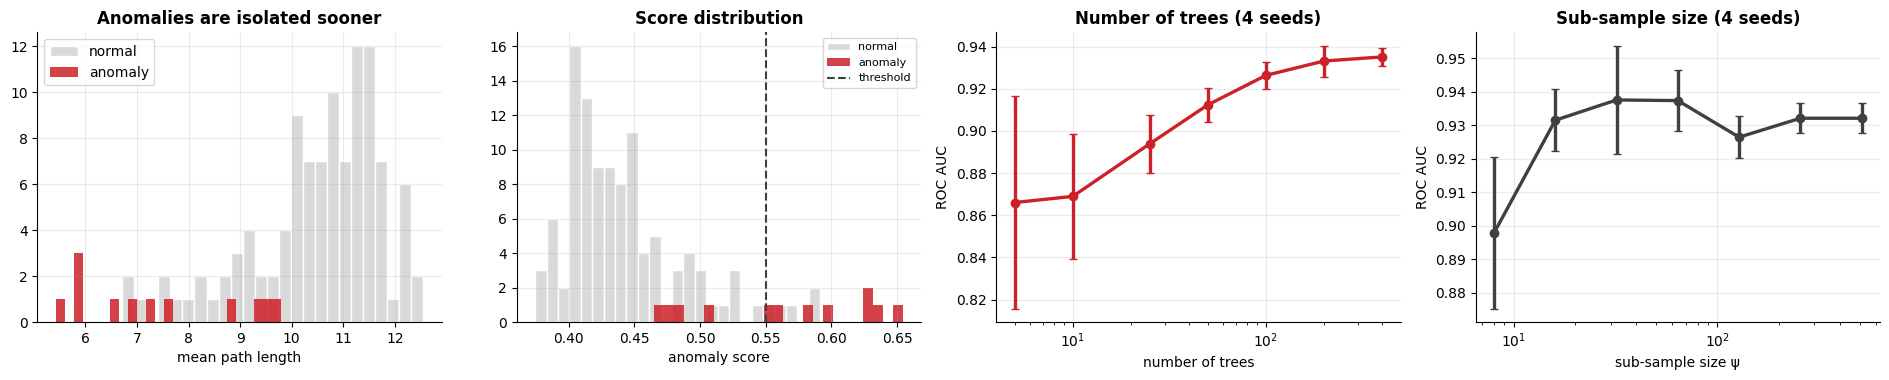

In [25]:
#Path Lengths, Score Distribution and Sensitivity to the Number of Trees and the Sub-Sample Size
path = iforest.mean_path(X_anom)
fig, axes = plt.subplots(1, 4, figsize=(19, 3.9))
axes[0].hist(path[y_anom == 0], bins=25, color=LIGHT, edgecolor="white", label="normal"); axes[0].hist(path[y_anom == 1], bins=25, color=RED, alpha=0.85, label="anomaly"); axes[0].set_xlabel("mean path length"); axes[0].set_title("Anomalies are isolated sooner"); axes[0].legend()
axes[1].hist(score_if[y_anom == 0], bins=25, color=LIGHT, edgecolor="white", label="normal"); axes[1].hist(score_if[y_anom == 1], bins=25, color=RED, alpha=0.85, label="anomaly"); axes[1].axvline(thr, color=DARK, ls="--", label="threshold"); axes[1].set_xlabel("anomaly score"); axes[1].set_title("Score distribution"); axes[1].legend(fontsize=8)
trees_sweep = [5, 10, 25, 50, 100, 200, 400]
auc_trees = [[roc_auc_score(y_anom, IsolationForestScratch(n_trees=nt, max_samples=128, seed=s).fit(normal_tr).score(X_anom)) for s in range(4)] for nt in trees_sweep]
axes[2].errorbar(trees_sweep, np.mean(auc_trees, axis=1), yerr=np.std(auc_trees, axis=1), marker="o", color=RED, lw=2.4, capsize=3); axes[2].set_xscale("log"); axes[2].set_xlabel("number of trees"); axes[2].set_ylabel("ROC AUC"); axes[2].set_title("Number of trees (4 seeds)")
psi_sweep = [8, 16, 32, 64, 128, 256, 512]
auc_psi = [[roc_auc_score(y_anom, IsolationForestScratch(n_trees=100, max_samples=p, seed=s).fit(normal_tr).score(X_anom)) for s in range(4)] for p in psi_sweep]
axes[3].errorbar(psi_sweep, np.mean(auc_psi, axis=1), yerr=np.std(auc_psi, axis=1), marker="o", color=DARK, lw=2.4, capsize=3); axes[3].set_xscale("log"); axes[3].set_xlabel("sub-sample size ψ"); axes[3].set_ylabel("ROC AUC"); axes[3].set_title("Sub-sample size (4 seeds)")
plt.tight_layout(); plt.show()

,ROC AUC,PR AUC
detector,,
Isolation Forest (scratch),0.935,0.715
Isolation Forest (scikit-learn),0.935,0.745
One-Class SVM (ν = 0.05),0.897,0.605
One-Class SVM (ν = 0.2),0.893,0.556
LOF (novelty),0.878,0.595


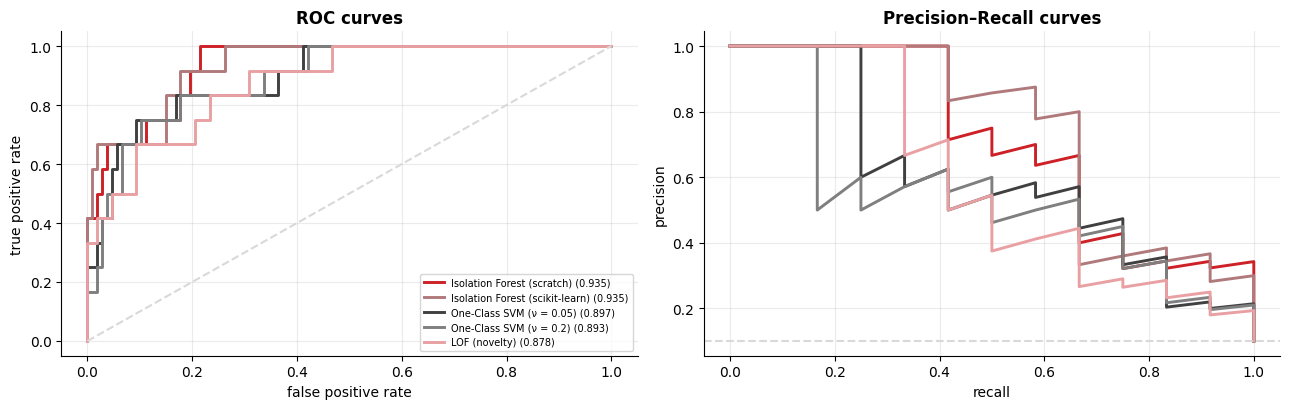

In [26]:
#Comparison with Other Novelty Detectors: One-Class SVM and Local Outlier Factor ( Trained on Benign Only )
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor

detectors = {"Isolation Forest (scratch)": score_if, "Isolation Forest (scikit-learn)": -sk_if.score_samples(X_anom),
             "One-Class SVM (ν = 0.05)": -OneClassSVM(nu=0.05, gamma="scale").fit(normal_tr).score_samples(X_anom),
             "One-Class SVM (ν = 0.2)": -OneClassSVM(nu=0.2, gamma="scale").fit(normal_tr).score_samples(X_anom),
             "LOF (novelty)": -LocalOutlierFactor(n_neighbors=20, novelty=True).fit(normal_tr).score_samples(X_anom)}
rows = [{"detector": n, "ROC AUC": roc_auc_score(y_anom, s), "PR AUC": average_precision_score(y_anom, s)} for n, s in detectors.items()]
det_df = pd.DataFrame(rows).set_index("detector")
display(det_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for (name, s), color in zip(detectors.items(), [RED, "#B07A7C", DARK, GRAY, SOFT]):
    f, t, _ = roc_curve(y_anom, s); axes[0].plot(f, t, color=color, lw=2.1, label=f"{name} ({roc_auc_score(y_anom, s):.3f})")
    p, r, _ = precision_recall_curve(y_anom, s); axes[1].plot(r, p, color=color, lw=2.1)
axes[0].plot([0, 1], [0, 1], color=LIGHT, ls="--"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate"); axes[0].set_title("ROC curves"); axes[0].legend(fontsize=7, loc="lower right")
axes[1].axhline(y_anom.mean(), color=LIGHT, ls="--"); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_title("Precision–Recall curves")
plt.tight_layout(); plt.show()

The Isolation Forest is the **best detector** here (AUC 0.935 vs 0.88–0.90) and our **from-scratch** version matches scikit-learn (same AUC, score correlation 0.98).

### **8. Summary**

,accuracy,recall,precision,F1,ROC AUC,PR AUC
SVM (default RBF),0.959,0.891,1.000,0.942,0.997,0.996
Logistic regression + GA subset,0.965,0.906,1.000,0.951,0.998,0.997
SVM (PSO-tuned),0.982,0.953,1.000,0.976,0.998,0.997
Fuzzy system,0.889,0.984,0.778,0.869,0.978,0.964


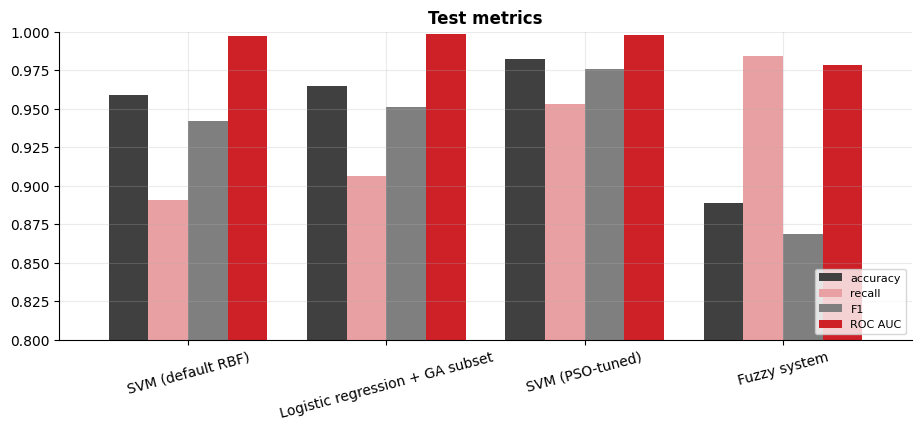

In [27]:
#Classification Models Built in This Notebook ( Malignant × Benign, Test Set ) and the Specific Metrics of Each Algorithm
comp = pd.DataFrame(results).T[["accuracy", "recall", "precision", "F1", "ROC AUC", "PR AUC"]]
display(comp.round(3))
comp[["accuracy", "recall", "F1", "ROC AUC"]].plot.bar(color=[DARK, SOFT, GRAY, RED], figsize=(11, 4), rot=15, width=0.8); plt.ylim(0.8, 1.0); plt.title("Test metrics"); plt.legend(loc="lower right", fontsize=8)
plt.show()

| | **SVM** | **Genetic algorithm** | **PSO** | **Simulated annealing** | **Fuzzy system** | **Isolation Forest** |
|---|---|---|---|---|---|---|
| Role | classifier | optimiser (subset search) | optimiser (continuous) | optimiser (combinatorial) | rule-based model | anomaly detector |
| Specific metrics | support vectors, margin, C × accuracy | convergence, diversity, stability across runs | convergence, swarm diversity, efficiency vs random/grid | tour length, acceptance rate, cooling schedule | rule activation, coverage, control surface | path length, score distribution, trees × ψ |
| Main risk | kernel and C/γ choice, scaling | premature convergence, cost of fitness | local optima, parameter tuning (w, c₁, c₂) | cooling schedule | rule design, curse of rules | needs the contamination threshold |
| Python | `SVC` | `deap`, `pygad` | `pyswarms` | `scipy.optimize.dual_annealing` | `scikit-fuzzy` | `IsolationForest` |

* **Metaheuristics** (GA, PSO, SA) need **no gradient**: they only need a **fitness function** – but the fitness must be evaluated **without touching the test set**
* Always report **stability across several runs**: a single lucky run proves nothing
* A **benchmark** against simple baselines (random search, grid, nearest neighbour, SelectKBest) is what shows whether the metaheuristic is worth its cost